# ML Experiment Results

Generic template notebook: loads every experiment JSON for one greenhouse +
target combination, builds summary tables and plots.

To create one of the four target notebooks (Alava/temperature,
Alava/rel_humidity, Cartagena/temperature, Cartagena/rel_humidity), copy
this notebook and only change `GREENHOUSE` and `TARGET` in the Config cell
below — everything else adapts automatically.


In [1]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.dpi"] = 110


## 1. Configuration

In [ ]:
# Greenhouse and target this notebook analyzes.
# GREENHOUSE: "alava" or "cartagena"
# TARGET:     "temperature" or "rel_humidity"
GREENHOUSE = "alava"
TARGET = "rel_humidity"

# Base results folder for this greenhouse (one subfolder per model:
# lstm/, gru/, cnn_lstm/, dlinear/, nlinear/, patchtst/, itransformer/).
RESULTS_DIR = Path(f"../results/experiments/{GREENHOUSE}")

# Glob pattern: picks up every model's JSON for the chosen target, e.g.
# results/experiments/alava/lstm/temperature/01_lstm_alava_temp.json
PATTERN = f"*/{TARGET}/*.json"


## 2. Load data

In [3]:
def experiment_name(path: Path) -> str:
    """Experiment name derived from the file name.

    By default uses the file name as-is (without extension). If your
    files include a repetition/seed suffix you want to ignore when
    grouping (e.g. 'my_experiment_seed3.json'), adjust the regex here,
    for example:
        return re.sub(r"_seed\d+$", "", path.stem)
    """
    return path.stem


def load_results(directory: Path, pattern: str = "*.json"):
    """Loads every result JSON into a list of dicts, adding file/experiment
    metadata.

    Supports two file formats:
    - A single results dict per file: {..., "metrics": {...}}
    - A list of results dicts per file: [{...}, {...}, ...]
      (each list element is treated as a distinct repetition/run of the
      same file, and numbered automatically). This is the normal case
      here: each experiment script appends one entry per run to its JSON,
      so a script run 3 times produces a 3-element list.
    """
    files = sorted(Path(directory).glob(pattern))
    if not files:
        raise FileNotFoundError(f"No '{pattern}' files found in {directory}")

    data = []
    for f in files:
        with open(f, "r", encoding="utf-8") as fh:
            content = json.load(fh)

        # Normalize to a list of dicts, however the file is shaped
        if isinstance(content, dict):
            items = [content]
        elif isinstance(content, list):
            items = content
        else:
            raise ValueError(f"Unexpected format in {f.name}: expected dict or list, "
                              f"got {type(content)}")

        for i, d in enumerate(items):
            if not isinstance(d, dict):
                raise ValueError(f"Item {i} of {f.name} is not a dict (it's {type(d)})")
            d = dict(d)  # copy so we don't mutate the original
            d["_file"] = f.name if len(items) == 1 else f"{f.name}[{i}]"
            d["_experiment"] = experiment_name(f)
            data.append(d)
    return data


results = load_results(RESULTS_DIR, PATTERN)
print(f"Loaded {len(results)} result files, "
      f"corresponding to {len(set(d['_experiment'] for d in results))} distinct experiment(s).")


Loaded 33 result files, corresponding to 7 distinct experiment(s).


<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:8: SyntaxWarning: invalid escape sequence '\d'
C:\Users\jclps\AppData\Local\Temp\ipykernel_16816\1520848580.py:8: SyntaxWarning: invalid escape sequence '\d'
  return re.sub(r"_seed\d+$", "", path.stem)


## 3. Building the DataFrames

In [4]:
def build_global_df(data):
    rows = []
    for d in data:
        row = {"experiment": d["_experiment"], "file": d["_file"]}
        row.update(d["metrics"]["global"])
        rows.append(row)
    return pd.DataFrame(rows)


def build_horizon_df(data):
    rows = []
    for d in data:
        for h_key, metrics in d["metrics"]["per_horizon"].items():
            row = {
                "experiment": d["_experiment"],
                "file": d["_file"],
                "horizon": int(h_key.split("_")[1]),
            }
            row.update(metrics)
            rows.append(row)
    return pd.DataFrame(rows)


def build_month_df(data):
    rows = []
    for d in data:
        for month, metrics in d["metrics"].get("per_month", {}).items():
            row = {"experiment": d["_experiment"], "file": d["_file"], "month": month}
            row.update(metrics)
            rows.append(row)
    return pd.DataFrame(rows)


def build_day_night_df(data):
    rows = []
    for d in data:
        for period in ("day", "night"):
            metrics = d["metrics"].get(period)
            if metrics:
                row = {"experiment": d["_experiment"], "file": d["_file"], "period": period}
                row.update(metrics)
                rows.append(row)
    return pd.DataFrame(rows)


df_global = build_global_df(results)
df_horizon = build_horizon_df(results)
df_month = build_month_df(results)
df_day_night = build_day_night_df(results)

df_global.head()


,experiment,file,r2,mse,rmse,mae,mape,relative_error,relative_error_abs
0,06_cnn_lstm_alava_hum,06_cnn_lstm_alava_hum.json[0],0.743,91.783,9.580,6.721,15.021,0.036,0.150
1,06_cnn_lstm_alava_hum,06_cnn_lstm_alava_hum.json[1],0.745,91.256,9.553,6.589,14.989,0.037,0.150
2,06_cnn_lstm_alava_hum,06_cnn_lstm_alava_hum.json[2],0.740,92.986,9.643,6.653,15.265,0.036,0.153
3,06_cnn_lstm_alava_hum,06_cnn_lstm_alava_hum.json[3],0.746,90.947,9.537,6.582,14.994,0.051,0.150
4,06_cnn_lstm_alava_hum,06_cnn_lstm_alava_hum.json[4],0.754,87.957,9.379,6.495,14.547,0.032,0.145


## 4. Global metrics table (mean ± std per experiment)

In [5]:
GLOBAL_METRICS = ["r2", "mse", "rmse", "mae", "mape"]  #, "relative_error", "relative_error_abs"]

global_table = (
    df_global
    .groupby("experiment")[GLOBAL_METRICS]
    .agg(["mean", "std"])
    .round(4)
)

# Flatten the multi-index columns, e.g. ('r2', 'mean') -> 'r2_mean'
global_table.columns = [f"{metric}_{stat}" for metric, stat in global_table.columns]
global_table = global_table.sort_index()
global_table


,r2_mean,r2_std,mse_mean,mse_std,rmse_mean,rmse_std,mae_mean,mae_std,mape_mean,mape_std
experiment,,,,,,,,,,
02_lstm_alava_hum,0.743,0.001,92.016,0.510,9.592,0.026,6.642,0.027,15.197,0.165
04_gru_alava_hum,0.742,0.002,92.122,0.839,9.598,0.044,6.641,0.044,15.116,0.097
06_cnn_lstm_alava_hum,0.746,0.005,90.986,1.863,9.538,0.098,6.608,0.084,14.963,0.260
07_dlinear_alava,0.787,0.003,76.097,1.153,8.723,0.066,6.128,0.030,12.729,0.200
08_nlinear_alava,0.783,0.002,77.661,0.863,8.812,0.049,6.166,0.062,12.614,0.188
09_patchtst_alava,0.822,0.003,63.519,1.184,7.970,0.074,5.614,0.062,11.688,0.164
10_itransformer_alava,0.829,0.002,61.015,0.617,7.811,0.040,5.489,0.024,11.416,0.117


### Compact 'mean ± std' version, easier to read

In [6]:
def mean_std_table(df, metrics, group_cols):
    agg = df.groupby(group_cols)[metrics].agg(["mean", "std"])
    out = pd.DataFrame(index=agg.index)
    for m in metrics:
        mean = agg[(m, "mean")]
        std = agg[(m, "std")].fillna(0)
        out[m] = [f"{mu:.3f} \u00b1 {sd:.3f}" for mu, sd in zip(mean, std)]
    return out.sort_index()


compact_global_table = mean_std_table(df_global, GLOBAL_METRICS, ["experiment"])
compact_global_table


,r2,mse,rmse,mae,mape
experiment,,,,,
02_lstm_alava_hum,0.743 ± 0.001,92.016 ± 0.510,9.592 ± 0.027,6.642 ± 0.027,15.197 ± 0.165
04_gru_alava_hum,0.742 ± 0.002,92.122 ± 0.839,9.598 ± 0.044,6.641 ± 0.044,15.116 ± 0.096
06_cnn_lstm_alava_hum,0.746 ± 0.005,90.986 ± 1.863,9.538 ± 0.098,6.608 ± 0.084,14.963 ± 0.259
07_dlinear_alava,0.787 ± 0.003,76.097 ± 1.153,8.723 ± 0.066,6.128 ± 0.030,12.729 ± 0.200
08_nlinear_alava,0.783 ± 0.002,77.661 ± 0.863,8.812 ± 0.049,6.166 ± 0.062,12.614 ± 0.188
09_patchtst_alava,0.822 ± 0.003,63.519 ± 1.184,7.970 ± 0.074,5.614 ± 0.062,11.687 ± 0.164
10_itransformer_alava,0.829 ± 0.002,61.015 ± 0.617,7.811 ± 0.040,5.489 ± 0.024,11.416 ± 0.117


In [7]:
compact_global_table.to_latex()


'\\begin{tabular}{llllll}\n\\toprule\n & r2 & mse & rmse & mae & mape \\\\\nexperiment &  &  &  &  &  \\\\\n\\midrule\n02_lstm_alava_hum & 0.743 ± 0.001 & 92.016 ± 0.510 & 9.592 ± 0.027 & 6.642 ± 0.027 & 15.197 ± 0.165 \\\\\n04_gru_alava_hum & 0.742 ± 0.002 & 92.122 ± 0.839 & 9.598 ± 0.044 & 6.641 ± 0.044 & 15.116 ± 0.096 \\\\\n06_cnn_lstm_alava_hum & 0.746 ± 0.005 & 90.986 ± 1.863 & 9.538 ± 0.098 & 6.608 ± 0.084 & 14.963 ± 0.259 \\\\\n07_dlinear_alava & 0.787 ± 0.003 & 76.097 ± 1.153 & 8.723 ± 0.066 & 6.128 ± 0.030 & 12.729 ± 0.200 \\\\\n08_nlinear_alava & 0.783 ± 0.002 & 77.661 ± 0.863 & 8.812 ± 0.049 & 6.166 ± 0.062 & 12.614 ± 0.188 \\\\\n09_patchtst_alava & 0.822 ± 0.003 & 63.519 ± 1.184 & 7.970 ± 0.074 & 5.614 ± 0.062 & 11.687 ± 0.164 \\\\\n10_itransformer_alava & 0.829 ± 0.002 & 61.015 ± 0.617 & 7.811 ± 0.040 & 5.489 ± 0.024 & 11.416 ± 0.117 \\\\\n\\bottomrule\n\\end{tabular}\n'

## 5. Metrics table by month and by day/night

In [8]:
MONTH_METRICS = ["r2", "mse", "rmse", "mae", "mape"]

month_table = mean_std_table(df_month, MONTH_METRICS, ["experiment", "month"])
month_table


r2              mse            rmse  \
experiment            month                                                     
02_lstm_alava_hum     2025-06  0.769 ± 0.007  111.043 ± 3.504  10.537 ± 0.167   
                      2025-07  0.751 ± 0.005  112.373 ± 2.133  10.600 ± 0.100   
                      2025-08  0.426 ± 0.017  205.810 ± 6.176  14.345 ± 0.216   
                      2025-09  0.584 ± 0.009   87.963 ± 1.895   9.378 ± 0.101   
                      2025-10  0.643 ± 0.006   83.378 ± 1.318   9.131 ± 0.072   
...                                      ...              ...             ...   
10_itransformer_alava 2025-10  0.779 ± 0.010   51.678 ± 2.268   7.188 ± 0.159   
                      2025-11  0.577 ± 0.023   65.960 ± 3.529   8.120 ± 0.219   
                      2025-12  0.678 ± 0.010   52.982 ± 1.609   7.278 ± 0.111   
                      2026-01  0.689 ± 0.012   51.423 ± 2.014   7.170 ± 0.141   
                      2026-02  0.646 ± 0.009   81.077 ± 2.134   9.004 ± 0.118   

                                         mae            mape  
experiment            month                                   
02_lstm_alava_hum     2025-06  7.516 ± 0.136  14.653 ± 0.299  
                      2025-07  7.141 ± 0.096  13.788 ± 0.225  
                      2025-08  9.739 ± 0.334  47.092 ± 1.723  
                      2025-09  6.633 ± 0.067  12.378 ± 0.105  
                      2025-10  6.118 ± 0.034  12.085 ± 0.078  
...                                      ...             ...  
10_itransformer_alava 2025-10  5.040 ± 0.055   9.874 ± 0.205  
                      2025-11  5.596 ± 0.107   9.206 ± 0.248  
                      2025-12  5.212 ± 0.098   9.887 ± 0.198  
                      2026-01  5.216 ± 0.102  12.096 ± 0.153  
                      2026-02  6.523 ± 0.155  12.180 ± 0.245  

[63 rows x 5 columns]

In [9]:
DAY_NIGHT_METRICS = ["r2", "mse", "rmse", "mae", "mape", "relative_error", "relative_error_abs"]

day_night_table = mean_std_table(df_day_night, DAY_NIGHT_METRICS, ["experiment", "period"])
day_night_table


r2              mse            rmse  \
experiment            period                                                   
02_lstm_alava_hum     day     0.665 ± 0.004  134.299 ± 1.535  11.589 ± 0.066   
                      night   0.795 ± 0.002   51.848 ± 0.523   7.201 ± 0.036   
04_gru_alava_hum      day     0.665 ± 0.003  134.295 ± 1.143  11.588 ± 0.049   
                      night   0.794 ± 0.004   52.058 ± 0.977   7.215 ± 0.068   
06_cnn_lstm_alava_hum day     0.668 ± 0.009  133.095 ± 3.446  11.536 ± 0.150   
                      night   0.798 ± 0.012   50.982 ± 2.948   7.138 ± 0.207   
07_dlinear_alava      day     0.742 ± 0.008  103.593 ± 3.140  10.177 ± 0.153   
                      night   0.802 ± 0.004   50.064 ± 0.915   7.075 ± 0.065   
08_nlinear_alava      day     0.737 ± 0.004  105.430 ± 1.591  10.268 ± 0.077   
                      night   0.797 ± 0.004   51.371 ± 0.926   7.167 ± 0.064   
09_patchtst_alava     day     0.781 ± 0.004   87.615 ± 1.589   9.360 ± 0.085   
                      night   0.837 ± 0.004   40.819 ± 0.994   6.389 ± 0.078   
10_itransformer_alava day     0.792 ± 0.004   83.495 ± 1.666   9.137 ± 0.091   
                      night   0.843 ± 0.002   39.733 ± 0.553   6.303 ± 0.044   

                                        mae            mape  relative_error  \
experiment            period                                                  
02_lstm_alava_hum     day     8.202 ± 0.056  22.448 ± 0.347   0.104 ± 0.006   
                      night   5.160 ± 0.019   8.308 ± 0.060  -0.033 ± 0.001   
04_gru_alava_hum      day     8.164 ± 0.033  22.293 ± 0.149   0.113 ± 0.005   
                      night   5.195 ± 0.061   8.298 ± 0.086  -0.030 ± 0.003   
06_cnn_lstm_alava_hum day     8.185 ± 0.104  22.017 ± 0.414   0.107 ± 0.008   
                      night   5.110 ± 0.141   8.262 ± 0.228  -0.027 ± 0.007   
07_dlinear_alava      day     7.432 ± 0.086  17.643 ± 0.406   0.093 ± 0.010   
                      night   4.892 ± 0.063   8.076 ± 0.041  -0.002 ± 0.008   
08_nlinear_alava      day     7.457 ± 0.138  17.327 ± 0.365   0.084 ± 0.003   
                      night   4.945 ± 0.054   8.151 ± 0.053  -0.005 ± 0.002   
09_patchtst_alava     day     6.854 ± 0.074  16.167 ± 0.211   0.073 ± 0.004   
                      night   4.446 ± 0.062   7.467 ± 0.159   0.009 ± 0.006   
10_itransformer_alava day     6.675 ± 0.054  15.755 ± 0.179   0.070 ± 0.008   
                      night   4.366 ± 0.034   7.308 ± 0.058   0.016 ± 0.002   

                             relative_error_abs  
experiment            period                     
02_lstm_alava_hum     day         0.224 ± 0.003  
                      night       0.083 ± 0.001  
04_gru_alava_hum      day         0.223 ± 0.001  
                      night       0.083 ± 0.001  
06_cnn_lstm_alava_hum day         0.220 ± 0.004  
                      night       0.083 ± 0.002  
07_dlinear_alava      day         0.176 ± 0.004  
                      night       0.081 ± 0.000  
08_nlinear_alava      day         0.173 ± 0.004  
                      night       0.082 ± 0.001  
09_patchtst_alava     day         0.162 ± 0.002  
                      night       0.075 ± 0.002  
10_itransformer_alava day         0.158 ± 0.002  
                      night       0.073 ± 0.001

## 6. Metric evolution across the prediction horizon

`plot_metric_by_horizon` plots a single metric for one or more experiments.
If an experiment has several repetitions (same `experiment`, different
files), the mean is drawn together with a shaded band of ± 1 standard
deviation.

The following cell (`plot_all_metrics_by_horizon`) reuses the same logic to
draw **every metric at once**, as a grid of subplots, so a single cell
produces the full picture instead of one plot per cell.


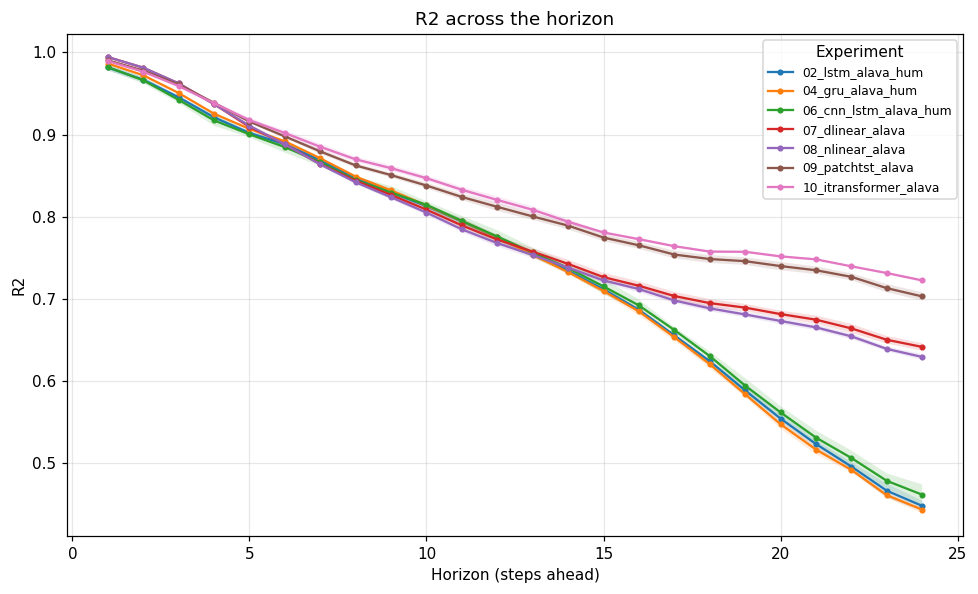

In [10]:
def plot_metric_by_horizon(df_horizon, experiments=None, metric="r2", ax=None,
                            figsize=(9, 5.5), title=None):
    """Plots the evolution of one metric (default r2) across the prediction
    horizon, for one or more experiments.

    Parameters
    ----------
    df_horizon : DataFrame returned by build_horizon_df
    experiments : str, list of str, or None (None = every available experiment)
    metric : metric column name to plot ('r2', 'mae', 'rmse', 'mape', ...)
    """
    if experiments is None:
        experiments = sorted(df_horizon["experiment"].unique())
    elif isinstance(experiments, str):
        experiments = [experiments]

    owns_figure = ax is None
    if owns_figure:
        fig, ax = plt.subplots(figsize=figsize)

    for experiment in experiments:
        subset = df_horizon[df_horizon["experiment"] == experiment]
        agg = subset.groupby("horizon")[metric].agg(["mean", "std"]).sort_index()
        ax.plot(agg.index, agg["mean"], marker="o", markersize=3, label=experiment)
        std = agg["std"].fillna(0)
        if (std > 0).any():
            ax.fill_between(agg.index, agg["mean"] - std, agg["mean"] + std, alpha=0.15)

    ax.set_xlabel("Horizon (steps ahead)")
    ax.set_ylabel(metric.upper() if metric in ("r2", "mae", "mse", "rmse") else metric)
    ax.set_title(title or f"{metric.upper()} across the horizon")
    ax.grid(alpha=0.3)
    ax.legend(title="Experiment", fontsize=8)
    if owns_figure:
        plt.tight_layout()
    return ax


plot_metric_by_horizon(df_horizon)
plt.show()


### All metrics at once

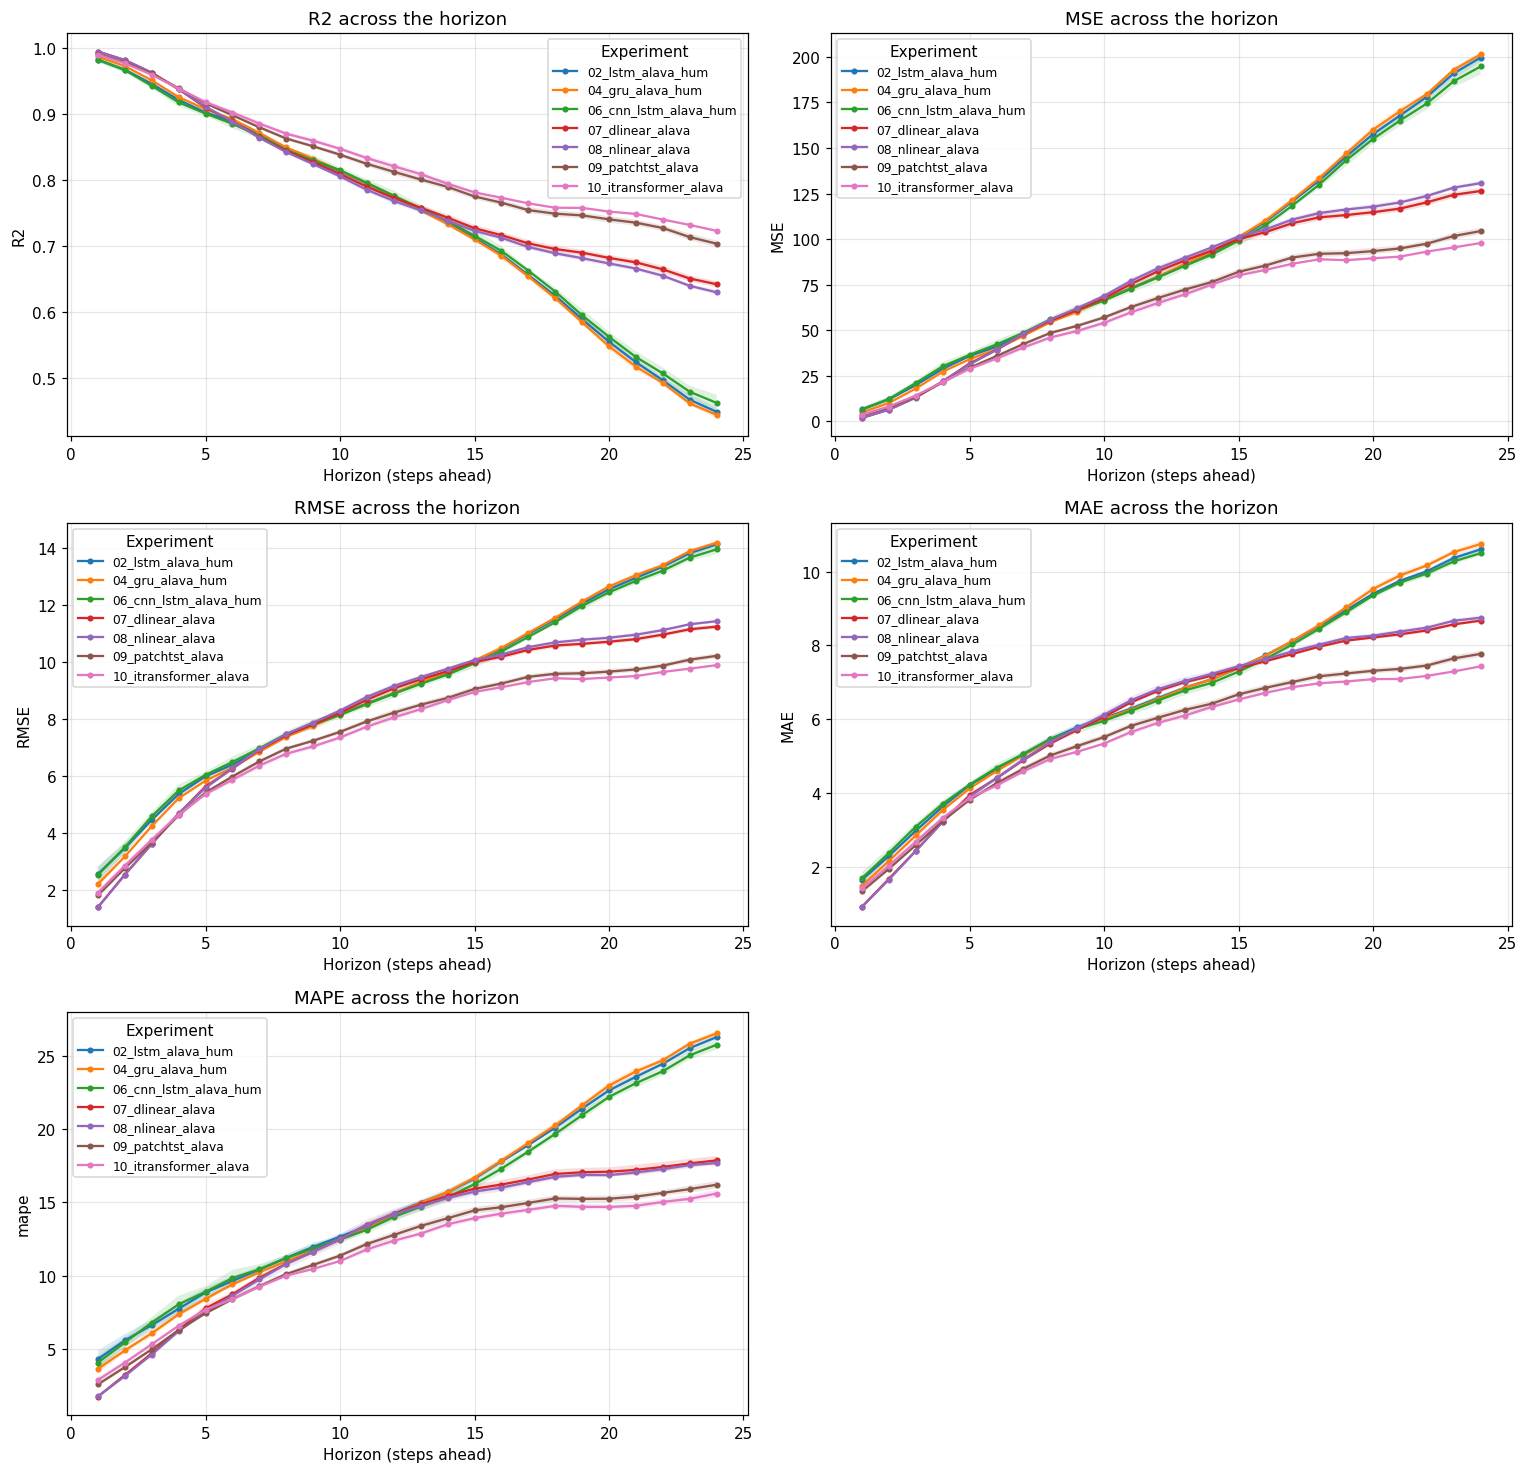

In [11]:
def plot_all_metrics_by_horizon(df_horizon, experiments=None,
                                 metrics=GLOBAL_METRICS, ncols=2, figsize=(7, 4.5)):
    """Draws one subplot per metric (all of GLOBAL_METRICS by default), each
    showing every experiment, in a single figure - the one-cell replacement
    for calling plot_metric_by_horizon once per metric.
    """
    nrows = -(-len(metrics) // ncols)  # ceil division
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize[0] * ncols, figsize[1] * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, metric in zip(axes, metrics):
        plot_metric_by_horizon(df_horizon, experiments=experiments, metric=metric, ax=ax)

    # Hide unused axes if metrics don't fill the grid exactly
    for ax in axes[len(metrics):]:
        ax.set_visible(False)

    fig.tight_layout()
    return fig


plot_all_metrics_by_horizon(df_horizon)
plt.show()
